In [1]:
from transformers import AutoTokenizer
import torch 
import numpy as np
import pickle
import os
import re
import glob
import re
from natsort import os_sorted
from scipy.spatial.distance import hamming
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tqdm.notebook import tqdm
import sys
sys.path.append('..')
from utils import model_to_path_dict

In [2]:
save_dir = '../../generated'
exclusion_dir = '../../behavior_data/exclusion'
original_transcript_dir = '../../behavior_data/transcripts/moth_stories'
model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
if model_name =='Llama3.2-3b-instruct_finetuned':
    tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.2-3B-Instruct")
else:
    tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
plot_fontsize = 8

In [ ]:
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

## reads each individual segmentation

In [4]:
from statsmodels.tsa.stattools import acf
from scipy.signal import correlate
def load_story_roc_test(story,threshold):
    story_exclusion = pd.read_csv(os.path.join(exclusion_dir,'%s_exclusion.csv'%story))
    excluded_subjects = story_exclusion['excluded'].loc[story_exclusion['segmentation']==1].values

    logit_dir = os.path.join(res_save_dir,story+'_instruct','subject_segmentation_logits')
    roc_dir = os.path.join(res_save_dir,story+'_instruct','roc')

    newline_prob_files = glob.glob(os.path.join(logit_dir,'newline_prob*.pkl'))
    block_sizes = []
    for file in newline_prob_files:
        block_size = 2
        #plt.figure()
        newline_prob = torch.load(file)
        #auto_corr = correlate(newline_prob/np.linalg.norm(newline_prob),newline_prob/np.linalg.norm(newline_prob))
        #plt.plot(auto_corr[int(len(auto_corr)/2):],label ='old')
        auto_corr_new = acf(newline_prob, nlags=400)
        #plt.plot(auto_corr_new,label = 'new')
        while auto_corr_new[block_size]>threshold:
            block_size+=1
        #print(auto_corr_new[block_size])
        block_sizes.append(block_size)
    return block_sizes

In [6]:
res_save_dir = os.path.join(save_dir,model_save_dir_name,'prolific_data')

def load_story_roc(story):
    story_exclusion = pd.read_csv(os.path.join(exclusion_dir,'%s_exclusion.csv'%story))
    excluded_subjects = story_exclusion['excluded'].loc[story_exclusion['segmentation']==1].values

    logit_dir = os.path.join(res_save_dir,story+'_instruct','subject_segmentation_logits')
    roc_dir = os.path.join(res_save_dir,story+'_instruct','roc')

    roc_files = os.listdir(roc_dir)
    roc_files = os_sorted(roc_files)
    roc_files = [f for f in roc_files if int(re.findall(r'\d+',f)[0]) not in excluded_subjects]
    
    all_sub_roc_dict = {} # contains fpr, tpr, and precision, recall
    for roc_file in roc_files:
        subject = int(re.findall(r'\d+',roc_file)[0])
        with open(os.path.join(roc_dir,roc_file),'rb') as f:
            sub_roc_dict = pickle.load(f)
        fpr = sub_roc_dict['fpr']
        tpr = sub_roc_dict['tpr']
#         ax.plot(fpr,tpr,alpha = 0.5)
        all_sub_roc_dict[subject] = sub_roc_dict
    
    
    perm_save_dir = os.path.join(res_save_dir,story+'_instruct','permutation_results')
    with open(os.path.join(perm_save_dir,'permutation_pvals.pkl'),'rb') as f:
        pvals = pickle.load(f)
    with open(os.path.join(perm_save_dir,'permutation_pr_pvals.pkl'),'rb') as f:
        pvals_pr = pickle.load(f)    
    
    return all_sub_roc_dict,pvals,pvals_pr

In [7]:
all_stories_results = {}
for story in stories:
    all_sub_roc_dict,pvals,pvals_pr = load_story_roc(story)
    all_stories_results[story] = {'roc_dict':all_sub_roc_dict,'pvals':pvals,'pvals_pr':pvals_pr}
    

Text(0.02, 0.5, 'True positive rate')

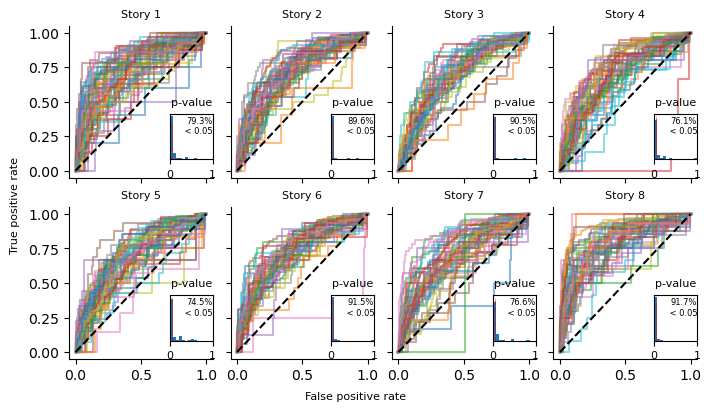

In [8]:
fig,axes = plt.subplots(figsize = (7,4),nrows = 2,ncols = 4,constrained_layout=True,sharey= True,sharex=True)
for story,ax in zip(stories,axes.flatten()):
    roc_dict = all_stories_results[story]['roc_dict']
    for subject in roc_dict.keys():
        tpr = roc_dict[subject]['tpr']
        fpr = roc_dict[subject]['fpr']
        ax.plot(fpr,tpr,alpha = 0.5)
    ax.set_title('Story %d'%story_to_idx_mapping[story],fontsize = plot_fontsize)
    xx = np.linspace(0,1,20)
    ax.plot(xx,xx,color = 'black',linestyle = '--')
    # --- inset histogram ---
    axins = ax.inset_axes([0.7, 0.12, 0.3, 0.3])  # [x0, y0, width, height] in axis fraction
    pvals = np.array(list(all_stories_results[story]['pvals'].values()))
    axins.hist(pvals,bins=np.linspace(0, 1, 15))  # adjust indexing if needed
    axins.vlines(x = 0.05,ymin=0,ymax = 40,color = 'red',lw = 0.5,linestyles = '-.')
    pct =np.sum((pvals<0.05))/len(pvals)*100
    
    axins.text(
        1, 0.95,
        f"{pct:.1f}%\n < 0.05",
        transform=axins.transAxes,
        ha='right', va='top',
        fontsize=6
    )
    axins.set_title('p-value',fontsize = plot_fontsize)
    axins.set_xlim(0, 1)
    axins.set_xticks([0,1]) 
    axins.set_xticklabels(['0', '1'],fontsize = plot_fontsize)
    axins.set_yticks([])
sns.despine()
fig.supxlabel('False positive rate',fontsize = plot_fontsize)
fig.supylabel('True positive rate',fontsize = plot_fontsize)

Text(0.02, 0.5, 'Recall')

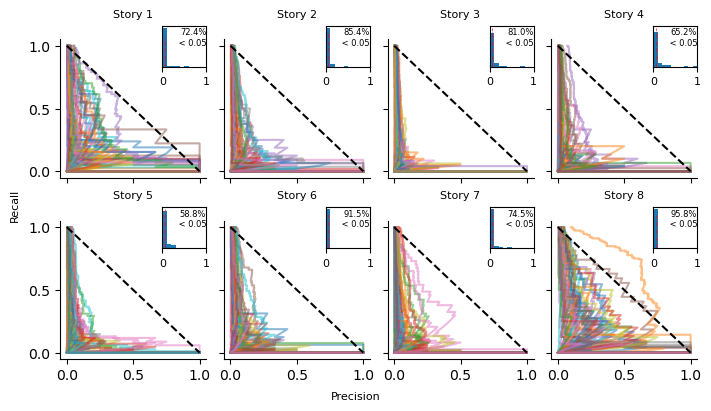

In [9]:
fig,axes = plt.subplots(figsize = (7,4),nrows = 2,ncols = 4,constrained_layout=True,sharey= True,sharex=True)
for story,ax in zip(stories,axes.flatten()):
    roc_dict = all_stories_results[story]['roc_dict']
    for subject in roc_dict.keys():
        precision = roc_dict[subject]['precision']
        recall = roc_dict[subject]['recall']
        ax.plot(precision,recall,alpha = 0.5)
    ax.set_title('Story %d'%story_to_idx_mapping[story],fontsize = plot_fontsize)
    xx = np.linspace(0,1,20)
    ax.plot(xx,xx[::-1],color = 'black',linestyle = '--')
    # --- inset histogram ---
    axins = ax.inset_axes([0.7, 0.8, 0.3, 0.3])  # [x0, y0, width, height] in axis fraction
    pvals = np.array(list(all_stories_results[story]['pvals_pr'].values()))
    axins.hist(pvals,bins=np.linspace(0, 1, 11))  # adjust indexing if needed

    axins.vlines(x = 0.05,ymin=0,ymax = 40,color = 'red',lw = 0.5,linestyles = '-.')
    pct =np.sum((pvals<0.05))/len(pvals)*100
    
    axins.text(
        1, 0.95,
        f"{pct:.1f}%\n < 0.05",
        transform=axins.transAxes,
        ha='right', va='top',
        fontsize=6
    )
    
    axins.set_xlim(0, 1)
    axins.set_xticks([0,1])    
    axins.set_xticklabels(['0', '1'],fontsize = plot_fontsize)
    axins.set_yticks([])
sns.despine()
fig.supxlabel('Precision',fontsize = plot_fontsize)
fig.supylabel('Recall',fontsize = plot_fontsize)

## use regression from Kumar et al. to predict individual subject segmentation

In [18]:
features = ['ce','kl','kl_punctuated','kl_punctuated_kumar']
feat_plotting_name = {'ce': 'Surprisal','kl':'KL Divergence',
                      'kl_punctuated':'KL Divergence, Punctuated',
                      'kl_punctuated_kumar':'KL Divergece, Punctuated, skip punctuation'
                     }
nfeats = [10,20]
stat = 'Pearson'
reg_model = 'Lasso'
regression_save_dir = os.path.join(save_dir,model_save_dir_name,'segmentation_regression')

In [11]:
def plot_auc_regression(test_story_tpr_fpr,test_story_pval,feat,nfeat):
    fig,axes = plt.subplots(figsize = (7,4),nrows = 2,ncols = 4,constrained_layout=True,sharey= True,sharex=True)
    for story_idx,ax in zip(range(1,len(stories)+1),axes.flatten()):
        roc_dict = test_story_tpr_fpr[story_idx]
        for sub_dict in roc_dict:
            tpr = sub_dict['tpr']
            fpr = sub_dict['fpr']
            ax.plot(fpr,tpr,alpha = 0.5)
        ax.set_title('Story %d'%story_idx,fontsize = plot_fontsize)
        xx = np.linspace(0,1,20)
        ax.plot(xx,xx,color = 'black',linestyle = '--')
        # --- inset histogram ---
        axins = ax.inset_axes([0.7, 0.12, 0.3, 0.3])  # [x0, y0, width, height] in axis fraction
        pvals = np.array(test_story_pval[story_idx])
        axins.hist(pvals,bins=np.linspace(0, 1, 15))  # adjust indexing if needed
        axins.vlines(x = 0.05,ymin=0,ymax = 40,color = 'red',lw = 0.5,linestyles = '-.')
        pct =np.sum((pvals<0.05))/len(pvals)*100

        axins.text(
            1, 0.95,
            f"{pct:.1f}%\n < 0.05",
            transform=axins.transAxes,
            ha='right', va='top',
            fontsize=6
        )
        axins.set_title('p-value',fontsize = plot_fontsize)
        axins.set_xlim(0, 1)
        axins.set_xticks([0,1]) 
        axins.set_xticklabels(['0', '1'],fontsize = plot_fontsize)
        axins.set_yticks([])
    sns.despine()
    fig.supxlabel('False positive rate',fontsize = plot_fontsize)
    fig.supylabel('True positive rate',fontsize = plot_fontsize)
    fig.suptitle('Regression: feature = %s, number of features = %d'%(feat,nfeat),fontsize = plot_fontsize)

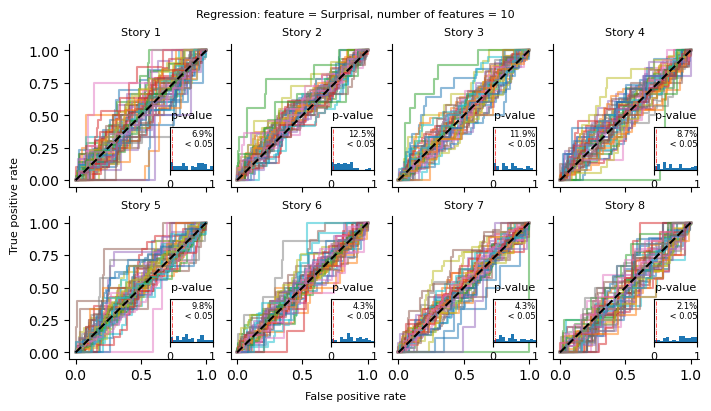

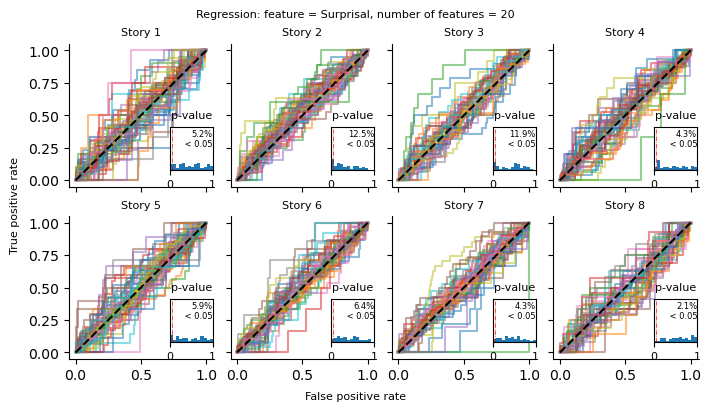

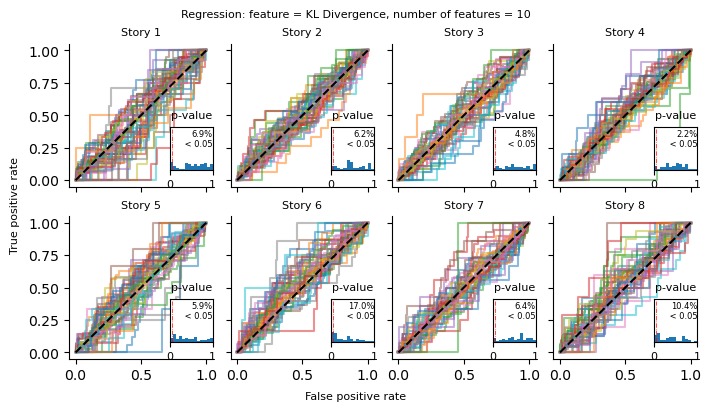

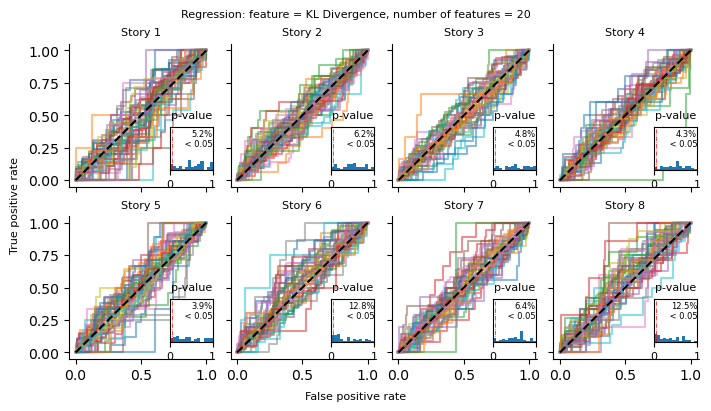

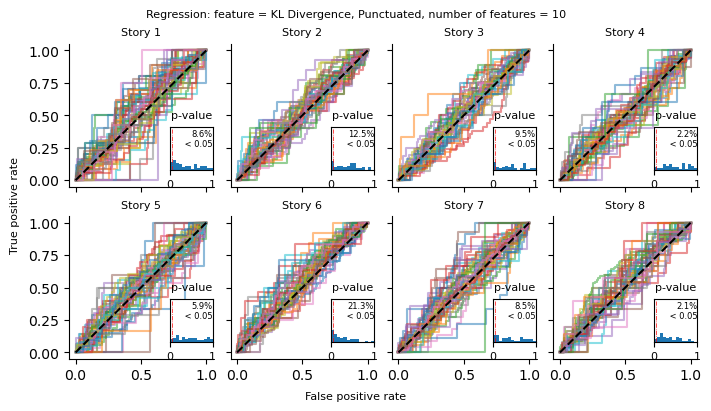

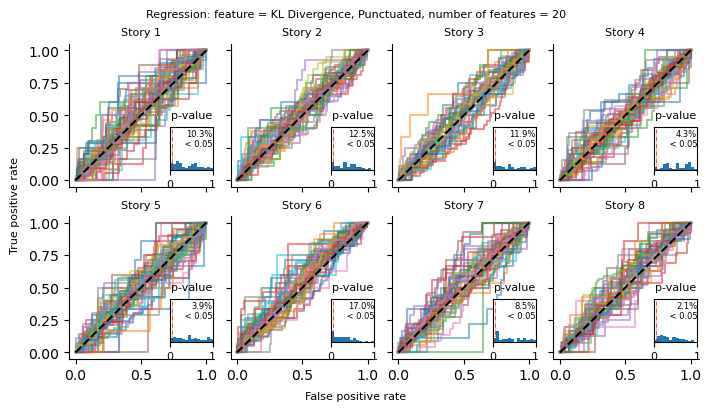

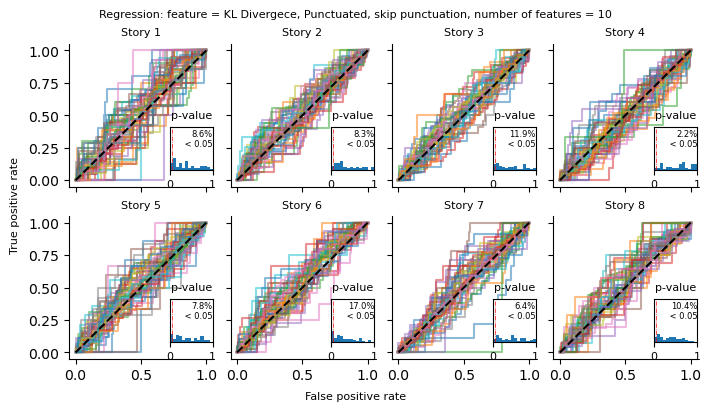

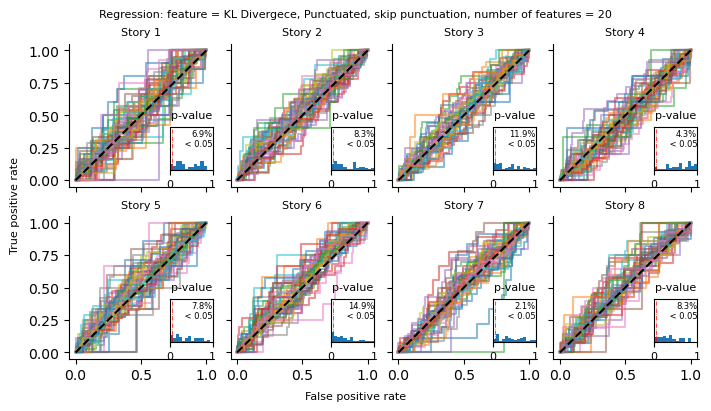

In [19]:
for feature in features:
    for nfeat in nfeats:
        with open(os.path.join(regression_save_dir,'roc_result_%s_%i_%s_%s.pkl'%(feature,nfeat,reg_model,stat)),'rb') as f:
            roc_result = pickle.load(f)
        test_story_tpr_fpr = roc_result['test_story_tpr_fpr']
        test_story_pval = roc_result['test_story_pval']
        test_story_auc = roc_result['test_story_auc']
        plot_auc_regression(test_story_tpr_fpr,test_story_pval,feat_plotting_name[feature],nfeat)

        